# Лабораторная работа №2. Рекомендательные системы

Попович Виталий Сергеевич, M3407

Датасет: UCI Online Retail - https://archive.ics.uci.edu/dataset/352/online+retail

**Целевая переменная - что именно мы рекомендуем:** товары (`StockCode`). Задача - top-10 personalized рекомендаций товаров, которые идентифицированный покупатель купит в своих будущих транзакциях. Рейтингов нет: сигнал - сам факт и количество покупок (implicit feedback).

| Колонка источника | колонка | Смысл |
|---|---|---|
| CustomerID | user_id | покупатель |
| StockCode | item_id | товар (рекомендуемый объект) |
| InvoiceNo | basket_id | чек/корзина (аналог session_id) |
| InvoiceDate | event_time | время события |
| Quantity | event_quantity | количество единиц |
| UnitPrice | unit_price | цена за единицу |
| - (вычисляемая) | line_amount | сумма строки чека |

In [33]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import io
import warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix, diags
from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import CosineRecommender

warnings.filterwarnings("ignore", message="Method expects CSR input")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

ONLINE_RETAIL_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
dataset_is_synthetic_stub = False

http_response = requests.get(ONLINE_RETAIL_URL, timeout=180)
http_response.raise_for_status()
try:
    raw_retail_df = pd.read_excel(io.BytesIO(http_response.content), dtype={"InvoiceNo": str, "StockCode": str}, engine="calamine")
except Exception:
    raw_retail_df = pd.read_excel(io.BytesIO(http_response.content), dtype={"InvoiceNo": str, "StockCode": str})
interactions_df = pd.DataFrame({
    "user_id": raw_retail_df["CustomerID"].astype("Int64").astype(str).where(raw_retail_df["CustomerID"].notna(), np.nan),
    "item_id": raw_retail_df["StockCode"],
    "basket_id": raw_retail_df["InvoiceNo"],
    "event_time": pd.to_datetime(raw_retail_df["InvoiceDate"]),
    "event_quantity": raw_retail_df["Quantity"],
    "unit_price": raw_retail_df["UnitPrice"],
})

interactions_df["line_amount"] = interactions_df["event_quantity"] * interactions_df["unit_price"]
dataset_source_label = "UCI Online Retail"
print(f"Источник данных: {dataset_source_label}")
print(f"Размер таблицы взаимодействий: {interactions_df.shape}")
interactions_df.head()

Источник данных: UCI Online Retail
Размер таблицы взаимодействий: (541909, 7)


,user_id,item_id,basket_id,event_time,event_quantity,unit_price,line_amount
0,17850,85123A,536365,2010-12-01 08:26:00,6,2.55,15.30
1,17850,71053,536365,2010-12-01 08:26:00,6,3.39,20.34
2,17850,84406B,536365,2010-12-01 08:26:00,8,2.75,22.00
3,17850,84029G,536365,2010-12-01 08:26:00,6,3.39,20.34
4,17850,84029E,536365,2010-12-01 08:26:00,6,3.39,20.34


**Результат загрузки:** 541 909 строк × 7 колонок; период 2010-12-01 - 2011-12-09; 4 372 уникальных покупателя, 4 070 кодов товаров, 25 900 чеков. Если в print указан `SYNTHETIC STUB`, весь пайплайн ниже остается работоспособным, но интерпретации относятся к демонстрационным данным.

**Разведочный анализ данных (EDA): постановка целей**

Начинаем со статистик: `info()`, `describe()`, пропуски, дубли, выбросы.

In [23]:
interactions_df.info()
display(interactions_df.describe().T)
missing_values_report = interactions_df.isna().sum().to_frame("missing_count")
display(missing_values_report)
duplicate_row_count = int(interactions_df.duplicated().sum())
cancellation_row_count = int((interactions_df["event_quantity"] < 0).sum())
nonpositive_price_row_count = int((interactions_df["unit_price"] <= 0).sum())
guest_row_count = int(interactions_df["user_id"].isna().sum())
print(f"Полные дубликаты строк: {duplicate_row_count}")
print(f"Строки-возвраты (event_quantity < 0): {cancellation_row_count}")
print(f"Строки с неположительной ценой: {nonpositive_price_row_count}")
print(f"Гостевые строки без user_id: {guest_row_count}")
print(f"Уникальных идентифицированных пользователей: {interactions_df['user_id'].nunique()}")
print(f"Уникальных item_id: {interactions_df['item_id'].nunique()}")
print(f"Уникальных корзин/чеков: {interactions_df['basket_id'].nunique()}")
print(f"Период наблюдений: {interactions_df['event_time'].min()} - {interactions_df['event_time'].max()}")
outlier_quantile_report = interactions_df[["event_quantity", "unit_price", "line_amount"]].quantile([0.5, 0.99, 0.999, 1.0])
display(outlier_quantile_report)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   user_id         406829 non-null  str           
 1   item_id         541909 non-null  str           
 2   basket_id       541909 non-null  str           
 3   event_time      541909 non-null  datetime64[us]
 4   event_quantity  541909 non-null  int64         
 5   unit_price      541909 non-null  float64       
 6   line_amount     541909 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 28.9 MB


,count,mean,min,25%,50%,75%,max,std
event_time,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
event_quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
unit_price,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
line_amount,541909.0,17.987795,-168469.6,3.4,9.75,17.4,168469.6,378.810824


,missing_count
user_id,135080
item_id,0
basket_id,0
event_time,0
event_quantity,0
unit_price,0
line_amount,0


Полные дубликаты строк: 5270
Строки-возвраты (event_quantity < 0): 10624
Строки с неположительной ценой: 2517
Гостевые строки без user_id: 135080
Уникальных идентифицированных пользователей: 4372
Уникальных item_id: 4070
Уникальных корзин/чеков: 25900
Период наблюдений: 2010-12-01 08:26:00 - 2011-12-09 12:50:00


,event_quantity,unit_price,line_amount
0.500,3.00,2.0800,9.75
0.990,100.00,18.0000,180.00
0.999,468.92,205.5598,825.00
1.000,80995.00,38970.0000,168469.60


**Интерпретация статистик (значения контрольного прогона):**

- **Пропуски:** 135 080 строк (24.9%) без `user_id` - гостевые чеки. Персонализировать их невозможно и оценить по ним нельзя -> удаляем. Остальные колонки полные.
- **Дубликаты:** 5 270 полных дублей строк - артефакты выгрузки, двойной учет покупок завысил бы уверенность моделей -> удаляем.
- **Возвраты:** 10 624 строки с `event_quantity < 0` (чеки с префиксом "C", минимум −80 995) - это отмены покупок, а не положительный сигнал -> удаляем.
- **Неположительная цена:** 2 517 строк, включая служебные записи (`Adjust bad debt` с ценой −11 062.06) и нулевые цены -> удаляем; 
- **Выбросы:** медиана количества 3 при максимуме 80 995; медиана цены 2.08 при максимуме 38 970; std многократно больше mean - экстремально тяжелые хвосты (оптовики и служебные сборы).

Визуализиурем активность пользователей, популярность товаров, помесячная динамика, heatmap корреляций.

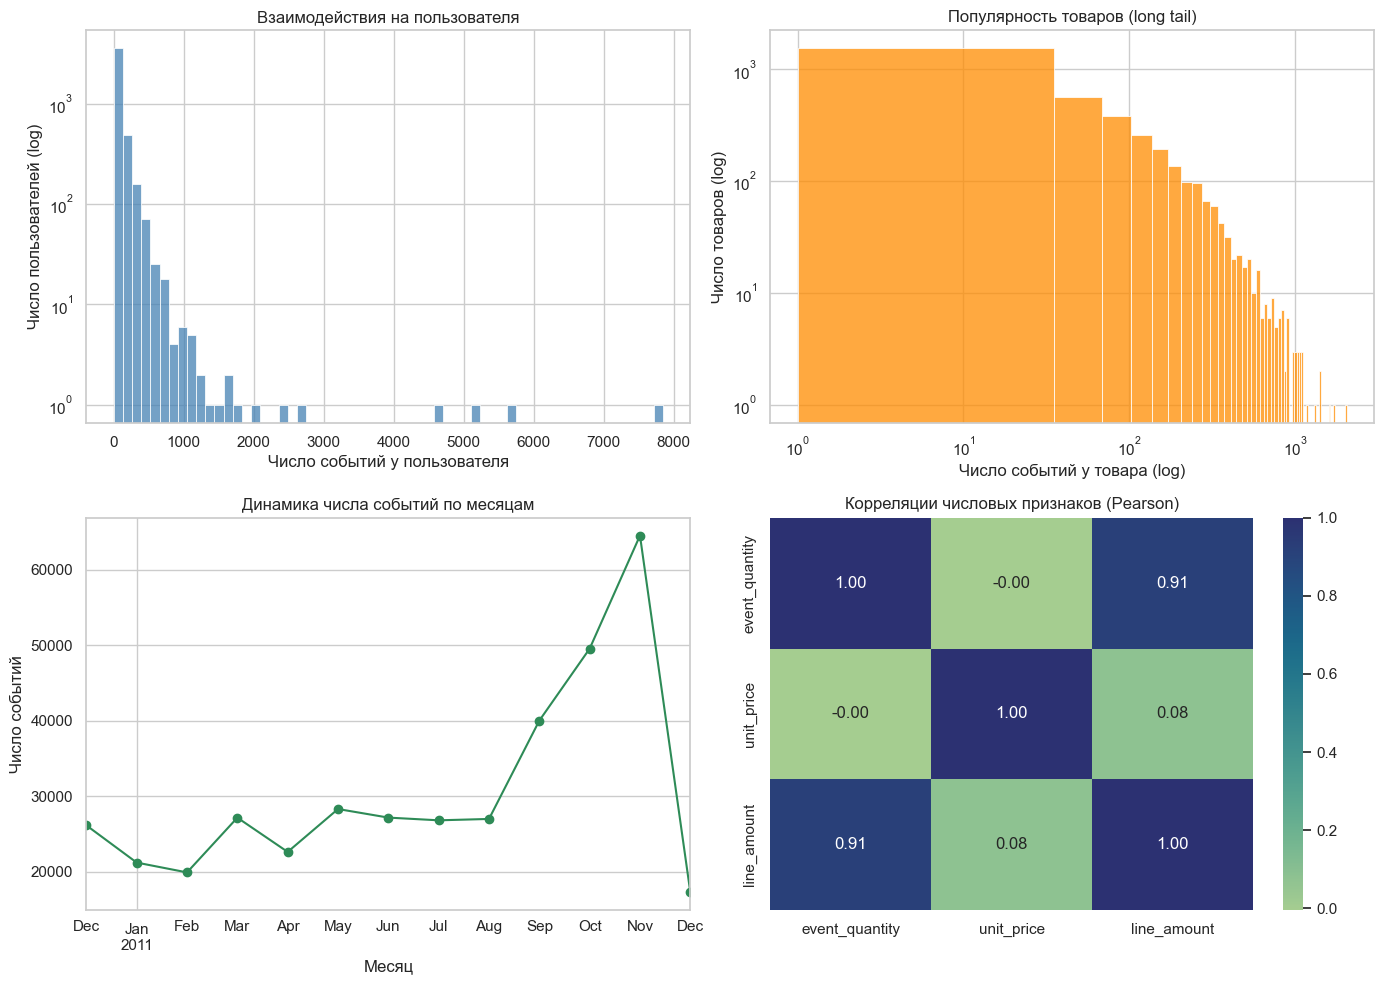

,Событий на пользователя,Событий на товар
Квантиль,,
0.00,1.00,1.00
0.25,17.00,12.00
0.50,41.00,49.00
0.75,100.00,135.00
0.90,208.00,284.00
0.95,314.15,401.80
0.99,668.30,811.96
1.00,7847.00,2035.00


,"Доля всех событий, %"
Верхние 1% товаров,9.81
Верхние 5% товаров,30.33
Верхние 10% товаров,45.66
Верхние 20% товаров,65.60


In [24]:
positive_identified_interactions = interactions_df.dropna(subset=["user_id"])
positive_identified_interactions = positive_identified_interactions[
    (positive_identified_interactions["event_quantity"] > 0)
    & (positive_identified_interactions["unit_price"] > 0)
]
events_per_user_eda = positive_identified_interactions.groupby("user_id").size()
events_per_item_eda = positive_identified_interactions.groupby("item_id").size()
monthly_event_counts = positive_identified_interactions.set_index("event_time").resample("MS").size()

eda_figure, eda_axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(events_per_user_eda, bins=60, ax=eda_axes[0, 0], color="steelblue")
eda_axes[0, 0].set_yscale("log")
eda_axes[0, 0].set_title("Взаимодействия на пользователя")
eda_axes[0, 0].set_xlabel("Число событий у пользователя")
eda_axes[0, 0].set_ylabel("Число пользователей (log)")
sns.histplot(events_per_item_eda, bins=60, ax=eda_axes[0, 1], color="darkorange")
eda_axes[0, 1].set_yscale("log")
eda_axes[0, 1].set_xscale("log")
eda_axes[0, 1].set_title("Популярность товаров (long tail)")
eda_axes[0, 1].set_xlabel("Число событий у товара (log)")
eda_axes[0, 1].set_ylabel("Число товаров (log)")
monthly_event_counts.plot(ax=eda_axes[1, 0], marker="o", color="seagreen")
eda_axes[1, 0].set_title("Динамика числа событий по месяцам")
eda_axes[1, 0].set_xlabel("Месяц")
eda_axes[1, 0].set_ylabel("Число событий")
numeric_correlation_matrix = positive_identified_interactions[["event_quantity", "unit_price", "line_amount"]].corr()
sns.heatmap(numeric_correlation_matrix, annot=True, fmt=".2f", cmap="crest", ax=eda_axes[1, 1])
eda_axes[1, 1].set_title("Корреляции числовых признаков (Pearson)")
eda_figure.tight_layout()
plt.show()
activity_quantiles = pd.DataFrame({
    "Событий на пользователя": events_per_user_eda.quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]),
    "Событий на товар": events_per_item_eda.quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]),
})
activity_quantiles.index.name = "Квантиль"
display(activity_quantiles.round(2))

item_popularity_sorted = events_per_item_eda.sort_values(ascending=False)
concentration_report = {}
for share in [0.01, 0.05, 0.10, 0.20]:
    top_item_count = max(1, int(np.ceil(len(item_popularity_sorted) * share)))
    concentration_report[f"Верхние {share:.0%} товаров"] = 100 * item_popularity_sorted.iloc[:top_item_count].sum() / item_popularity_sorted.sum()
display(pd.Series(concentration_report, name="Доля всех событий, %").to_frame().round(2))

**Подробная интерпретация визуализаций:**

1. **Активность пользователей (log-шкала Y):** распределение с тяжелым правым хвостом - медиана 41 событие, p90 = 208, p99 ≈ 668, максимум 7 847. Массовая часть покупателей имеет десятки событий, но есть длинная "голова" оптовиков и большой левый край с 1–4 событиями. Вывод: холодных пользователей (<5 событий) нужно отфильтровать - на них невозможно ни обучиться, ни честно выделить тест.
2. **Популярность товаров (log-log):** классический long tail - медиана 49 событий на товар, p99 ≈ 812, максимум 2 035. Небольшая группа хитов концентрирует непропорционально большую долю покупок. Следствия: (а) MostPop будет нетривиальным бейзлайном; (б) метрики точности обязаны дополняться Novelty/Coverage, иначе модель, рекомендующая только хиты, будет выглядеть "хорошей".
3. **Помесячная динамика:** выраженный рост к осени - с 26 157 событий (дек 2010) до 64 531 (ноя 2011); декабрь 2011 обрезан (данные до 09.12, 17 304 события). Данные нестационарны (тренд + предпраздничная сезонность) => случайное перемешивание строк при разделении недопустимо: будущее "протечет" в прошлое. Обосновано временное разделение.
4. **Heatmap корреляций:** `event_quantity` <> `line_amount` = 0.914 (сумма строки почти линейно определяется количеством - дешевый товар берут пачками), `unit_price` <> `line_amount` = 0.082, `event_quantity` <> `unit_price` ≈ −0.005. Цена практически не связана с объемом покупки => цена слабо информативна для ранжирования и в базовые модели не включается; признаки количества и суммы избыточны друг относительно друга.


**Вывод о качестве и план предобработки:** (1) удалить гостей; (2) удалить возвраты и неположительные цены; (4) удалить дубли; (5) отсечь выбросы по p99.9; (6) агрегировать строки чека в событие "покупка товара в корзине"; (7) отфильтровать холодных пользователей (<5 событий) и холодные товары (<5 покупателей).

In [25]:
rows_before_cleaning = len(interactions_df)
clean_interactions = interactions_df.dropna(subset=["user_id"]).copy()
clean_interactions = clean_interactions[~clean_interactions["basket_id"].astype(str).str.startswith("C")]
clean_interactions = clean_interactions[
    (clean_interactions["event_quantity"] > 0) & (clean_interactions["unit_price"] > 0)
]
if not dataset_is_synthetic_stub:
    clean_interactions = clean_interactions[clean_interactions["item_id"].str.match(r"^\d{5}[A-Za-z]{0,2}$")]
duplicate_rows_removed = int(clean_interactions.duplicated().sum())
clean_interactions = clean_interactions.drop_duplicates()
quantity_upper_bound = clean_interactions["event_quantity"].quantile(0.999)
price_upper_bound = clean_interactions["unit_price"].quantile(0.999)
clean_interactions = clean_interactions[
    (clean_interactions["event_quantity"] <= quantity_upper_bound)
    & (clean_interactions["unit_price"] <= price_upper_bound)
]
purchase_events = clean_interactions.groupby(["user_id", "item_id", "basket_id"], as_index=False).agg(
    event_time=("event_time", "min"), event_quantity=("event_quantity", "sum")
)
MIN_USER_EVENTS = 5
MIN_ITEM_USERS = 5
user_event_counts = purchase_events.groupby("user_id").size()
warm_user_ids = user_event_counts[user_event_counts >= MIN_USER_EVENTS].index
purchase_events = purchase_events[purchase_events["user_id"].isin(warm_user_ids)]
item_user_counts = purchase_events.groupby("item_id")["user_id"].nunique()
warm_item_ids = item_user_counts[item_user_counts >= MIN_ITEM_USERS].index
purchase_events = purchase_events[purchase_events["item_id"].isin(warm_item_ids)]
user_event_counts = purchase_events.groupby("user_id").size()
warm_user_ids = user_event_counts[user_event_counts >= MIN_USER_EVENTS].index
purchase_events = purchase_events[purchase_events["user_id"].isin(warm_user_ids)].reset_index(drop=True)
print(f"Строк до предобработки: {rows_before_cleaning}")
print(f"Удалено полных дублей: {duplicate_rows_removed}")
print(f"Границы отсечения выбросов: quantity <= {quantity_upper_bound:.0f}, unit_price <= {price_upper_bound:.2f}")
print(f"Строк-событий после предобработки: {len(purchase_events)}")
print(f"Пользователей после фильтрации: {purchase_events['user_id'].nunique()}")
print(f"Товаров после фильтрации: {purchase_events['item_id'].nunique()}")
print(f"Медиана событий на пользователя: {purchase_events.groupby('user_id').size().median():.1f}")

Строк до предобработки: 541909
Удалено полных дублей: 5189
Границы отсечения выбросов: quantity <= 504, unit_price <= 34.95
Строк-событий после предобработки: 383810
Пользователей после фильтрации: 4094
Товаров после фильтрации: 3133
Медиана событий на пользователя: 44.0


**Результаты предобработки:** 541 909 -> 383 810 событий покупок (−29%); удалено 5 189 дублей; границы выбросов: quantity <= 504, price <= 34.95; осталось **4 094 пользователя и 3 133 товара**, медиана 44 события на пользователя. Каждый элемент теперь - факт "товар куплен в конкретной корзине", сила сигнала - число таких корзин.

**Обоснование разделения данных.** Из EDA видно тренд и сезонность, поэтому используем **персональное временное разделение**: последние 20% событий каждого пользователя (по времени, минимум 1) -> test, остальные 80% -> train. Протокол оценки: релевантные test-товары = товары из теста, **не встречавшиеся в train** у этого пользователя; пользователи без таких товаров в оценке не участвуют.

In [26]:
TEST_FRACTION = 0.2
purchase_events = purchase_events.sort_values(["user_id", "event_time", "basket_id"]).reset_index(drop=True)
events_per_user_split = purchase_events.groupby("user_id")["item_id"].transform("size")
reverse_event_rank = purchase_events.groupby("user_id").cumcount(ascending=False)
test_events_per_user = np.maximum(1, np.ceil(TEST_FRACTION * events_per_user_split).astype(int))
is_test_event = reverse_event_rank < test_events_per_user
train_events = purchase_events.loc[~is_test_event].copy()
test_events = purchase_events.loc[is_test_event].copy()

all_user_ids = np.sort(purchase_events["user_id"].unique())
all_item_ids = np.sort(purchase_events["item_id"].unique())
user_id_to_index = {user_id: index for index, user_id in enumerate(all_user_ids)}
item_id_to_index = {item_id: index for index, item_id in enumerate(all_item_ids)}
for event_frame in (train_events, test_events):
    event_frame["user_index"] = event_frame["user_id"].map(user_id_to_index)
    event_frame["item_index"] = event_frame["item_id"].map(item_id_to_index)

train_purchase_counts = train_events.groupby(["user_index", "item_index"]).size().reset_index(name="purchase_count")
n_users = len(all_user_ids)
n_items = len(all_item_ids)
train_user_item_matrix = csr_matrix(
    (
        train_purchase_counts["purchase_count"].astype(np.float32).to_numpy(),
        (train_purchase_counts["user_index"].to_numpy(), train_purchase_counts["item_index"].to_numpy()),
    ),
    shape=(n_users, n_items),
)
train_seen_item_sets = {user_index: set(train_user_item_matrix.getrow(user_index).indices) for user_index in range(n_users)}
test_item_sets = test_events.groupby("user_index")["item_index"].apply(set).to_dict()
test_relevant_item_sets = {
    user_index: test_item_set - train_seen_item_sets.get(user_index, set())
    for user_index, test_item_set in test_item_sets.items()
}
test_relevant_item_sets = {user_index: item_set for user_index, item_set in test_relevant_item_sets.items() if len(item_set) > 0}
evaluated_user_indices = np.array(sorted(test_relevant_item_sets.keys()))
train_active_item_indices = np.sort(train_purchase_counts["item_index"].unique())
print(f"Train-событий: {len(train_events)}, Test-событий: {len(test_events)}")
print(f"Доля test-событий: {len(test_events) / len(purchase_events):.3f}")
print(f"Размер user-item матрицы: {train_user_item_matrix.shape}")
print(f"Плотность матрицы: {train_user_item_matrix.nnz / (n_users * n_items):.5f}")
print(f"Пользователей в оценке (есть новые товары в тесте): {len(evaluated_user_indices)}")
print(f"Товаров с поддержкой в train (кандидатов): {len(train_active_item_indices)}")
print(f"Медиана числа релевантных test-товаров: {np.median([len(item_set) for item_set in test_relevant_item_sets.values()]):.1f}")

Train-событий: 305437, Test-событий: 78373
Доля test-событий: 0.204
Размер user-item матрицы: (4094, 3133)
Плотность матрицы: 0.01715
Пользователей в оценке (есть новые товары в тесте): 3995
Товаров с поддержкой в train (кандидатов): 3124
Медиана числа релевантных test-товаров: 7.0


**Результаты разделения:** train 305 437 / test 78 373 событий (20.4% - как и задумано); CSR-матрица 4 094 × 3 133 с 219 939 ненулевых ячеек, плотность **1.72%** (98.3% нулей - типичная разреженность implicit-данных, что мотивирует матричную факторизацию). В оценке участвуют **3 995 пользователей** (97.6%), медиана релевантных test-товаров = 7. Кандидатов 3 124: 9 товаров встречаются только в тесте (холодный старт) - исключил

**Теоретическое обоснование методов**

1. **MostPop (бейзлайн):** глобальный топ товаров по числу уникальных покупателей, уже купленное пользователем исключается. Не персонализирован (кроме seen-фильтра), задает нижнюю планку качества и уровень "популярностного априора". При выраженном long tail обязан быть сильным - проверим.
2. **ItemKNN - `CosineRecommender` (метод ближайших соседей, item-based CF):** товары сравниваются косинусом их профилей покупок по пользователям; скор = сумма схожестей с K=50 ближайшими купленными товарами. Ловит локальные паттерны co-purchase ("купившие X берут Y"), интерпретируем, но чувствителен к разреженности и смещен к нишевым соседям.
3. **ALS - `AlternatingLeastSquares` (матричная факторизация):** разложение матрицы уверенности `1 + 15·purchase_count` на латентные факторы (64 размерности, регуляризация 0.05, 25 итераций). Улавливает глобальную скрытую структуру вкусов, устойчив к разреженности и шуму

Все модели обучаются только на train; уже купленные товары фильтруются, кандидаты ограничены товарами с поддержкой в train.
**Формализация.** $R_{ui}$ - число покупок товара $i$ пользователем $u$ в train.

- **MostPop:** $score(i)=\sum_u \mathbb{1}[R_{ui}>0]$ (число уникальных покупателей).
- **ItemKNN (cosine):** $sim(i,j)=\frac{R_{:,i}\cdot R_{:,j}}{\lVert R_{:,i}\rVert_2\,\lVert R_{:,j}\rVert_2}$, $score(u,i)=\sum_{j\in N_K(i)\cap I_u} sim(i,j)\,R_{uj}$, где $N_K(i)$ - $K=50$ ближайших товаров, $I_u$ - купленные пользователем.
- **ALS:** $p_{ui}=\mathbb{1}[R_{ui}>0]$, $c_{ui}=1+\alpha R_{ui}$ ($\alpha=15$); $\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\lVert X\rVert_F^2+\lVert Y\rVert_F^2)$, factors $=64$, $\lambda=0.05$, 25 итераций.

In [27]:
TOP_K = 10
item_train_user_counts = np.asarray((train_user_item_matrix > 0).sum(axis=0)).ravel()
popularity_ranked_item_indices = np.argsort(-item_train_user_counts, kind="stable")
popularity_ranked_item_indices = popularity_ranked_item_indices[item_train_user_counts[popularity_ranked_item_indices] > 0]

mostpop_recommendations = np.full((len(evaluated_user_indices), TOP_K), -1, dtype=np.int64)
for row_position, user_index in enumerate(evaluated_user_indices):
    seen_item_set = train_seen_item_sets[user_index]
    selected_item_indices = []
    for item_index in popularity_ranked_item_indices:
        if item_index not in seen_item_set:
            selected_item_indices.append(item_index)
            if len(selected_item_indices) == TOP_K:
                break
    mostpop_recommendations[row_position, : len(selected_item_indices)] = selected_item_indices

item_knn_model = CosineRecommender(K=50)
item_knn_model.fit(train_user_item_matrix, show_progress=False)
item_knn_recommendations, item_knn_scores = item_knn_model.recommend(
    evaluated_user_indices,
    train_user_item_matrix[evaluated_user_indices],
    N=TOP_K,
    filter_already_liked_items=True,
    items=train_active_item_indices,
)

als_model = AlternatingLeastSquares(factors=64, regularization=0.05, iterations=25, random_state=RANDOM_STATE)
als_confidence_matrix = (train_user_item_matrix * 15.0).tocsr()
als_model.fit(als_confidence_matrix, show_progress=False)
als_recommendations, als_scores = als_model.recommend(
    evaluated_user_indices,
    train_user_item_matrix[evaluated_user_indices],
    N=TOP_K,
    filter_already_liked_items=True,
    items=train_active_item_indices,
)
model_recommendations = {
    "MostPop": mostpop_recommendations,
    "ItemKNN": item_knn_recommendations,
    "ALS": als_recommendations,
}
for model_name, recommendation_matrix in model_recommendations.items():
    print(f"{model_name}: форма матрицы рекомендаций {recommendation_matrix.shape}")

MostPop: форма матрицы рекомендаций (3995, 10)
ItemKNN: форма матрицы рекомендаций (3995, 10)
ALS: форма матрицы рекомендаций (3995, 10)


**Результат обучения:** три матрицы рекомендаций формата (3 995 × 10) построены; ItemKNN и ALS каждая на матрице 4094×3133 . Значение −1 в строке означает нехватку кандидатов и корректно игнорируется метриками.

**Метрики качества, K = 10.** Выбраны 6 метрик (больше обязательного минимума), покрывающие точность, ранжирование и beyond-accuracy:

| Метрика | Тип | Смысл |
|---|---|---|
| **NDCG@10** | ранжирование | DCG с логарифмическим дисконтом позиции, нормированный на IDCG; бинарная релевантность; чувствительна к порядку попаданий |
| **Precision@10** | точность | доля попаданий среди 10 рекомендованных |
| **Recall@10** | полнота | доля найденных релевантных test-товаров пользователя |
| **Novelty@10** | специфическая RecSys | средняя self-information `−log2 p(item)` в битах (p - доля товара в train): выше => менее банальные, менее популярные рекомендации |
| **ILD@10** (Intra-List Diversity) | специфическая RecSys | `1 − средняя попарная косинусная схожесть` бинарных профилей товаров в списке: выше => разнообразнее выдача |
| **Coverage@10** | каталожная | доля каталога кандидатов, хотя бы раз попавшая в рекомендации всем пользователям |

Precision/Recall/NDCG усредняются по пользователям; Novelty и ILD - по пользователям и слотам; Coverage - глобально. Такой набор позволяет увидеть компромисс "точность <> новизна/охват", невидимый по одной метрике.

In [28]:
item_popularity_probability = item_train_user_counts / item_train_user_counts.sum()
item_self_information = -np.log2(np.maximum(item_popularity_probability, 1e-12))
item_profile_matrix = (train_user_item_matrix > 0).astype(np.float32).T.tocsr()
item_profile_norms = np.sqrt(np.asarray(item_profile_matrix.multiply(item_profile_matrix).sum(axis=1)).ravel())
item_profile_norms[item_profile_norms == 0] = 1.0
normalized_item_profiles = diags(1.0 / item_profile_norms) @ item_profile_matrix


def precision_at_k(recommended_items, relevant_item_set, k):
    valid_recommendations = recommended_items[recommended_items >= 0][:k]
    hit_count = sum(1 for item_index in valid_recommendations if item_index in relevant_item_set)
    return hit_count / k


def recall_at_k(recommended_items, relevant_item_set, k):
    valid_recommendations = recommended_items[recommended_items >= 0][:k]
    hit_count = sum(1 for item_index in valid_recommendations if item_index in relevant_item_set)
    return hit_count / len(relevant_item_set)


def ndcg_at_k(recommended_items, relevant_item_set, k):
    valid_recommendations = recommended_items[recommended_items >= 0][:k]
    relevance_gains = np.array([1.0 if item_index in relevant_item_set else 0.0 for item_index in valid_recommendations])
    discount_weights = 1.0 / np.log2(np.arange(2, len(valid_recommendations) + 2))
    discounted_cumulative_gain = float(np.sum(relevance_gains * discount_weights))
    ideal_hit_count = min(len(relevant_item_set), k)
    ideal_discount_weights = 1.0 / np.log2(np.arange(2, ideal_hit_count + 2))
    ideal_dcg = float(np.sum(ideal_discount_weights))
    return discounted_cumulative_gain / ideal_dcg if ideal_dcg > 0 else 0.0


def novelty_at_k(recommended_items, self_information_values, k):
    valid_recommendations = recommended_items[recommended_items >= 0][:k]
    if len(valid_recommendations) == 0:
        return 0.0
    return float(np.mean(self_information_values[valid_recommendations]))


def intra_list_diversity_at_k(recommended_items, profile_matrix, k):
    valid_recommendations = recommended_items[recommended_items >= 0][:k]
    if len(valid_recommendations) < 2:
        return 0.0
    similarity_block = (profile_matrix[valid_recommendations] @ profile_matrix[valid_recommendations].T).toarray()
    list_size = len(valid_recommendations)
    upper_triangle_indices = np.triu_indices(list_size, k=1)
    mean_pairwise_similarity = float(np.mean(similarity_block[upper_triangle_indices]))
    return 1.0 - mean_pairwise_similarity


evaluation_results = {}
for model_name, recommendation_matrix in model_recommendations.items():
    precision_scores = []
    recall_scores = []
    ndcg_scores = []
    novelty_scores = []
    diversity_scores = []
    recommended_item_union = set()
    for row_position, user_index in enumerate(evaluated_user_indices):
        relevant_item_set = test_relevant_item_sets[user_index]
        recommended_items = recommendation_matrix[row_position]
        precision_scores.append(precision_at_k(recommended_items, relevant_item_set, TOP_K))
        recall_scores.append(recall_at_k(recommended_items, relevant_item_set, TOP_K))
        ndcg_scores.append(ndcg_at_k(recommended_items, relevant_item_set, TOP_K))
        novelty_scores.append(novelty_at_k(recommended_items, item_self_information, TOP_K))
        diversity_scores.append(intra_list_diversity_at_k(recommended_items, normalized_item_profiles, TOP_K))
        recommended_item_union.update(int(item_index) for item_index in recommended_items if item_index >= 0)
    evaluation_results[model_name] = {
        f"Precision@{TOP_K}": float(np.mean(precision_scores)),
        f"Recall@{TOP_K}": float(np.mean(recall_scores)),
        f"NDCG@{TOP_K}": float(np.mean(ndcg_scores)),
        f"Novelty@{TOP_K}": float(np.mean(novelty_scores)),
        f"ILD@{TOP_K}": float(np.mean(diversity_scores)),
        f"Coverage@{TOP_K}": len(recommended_item_union) / len(train_active_item_indices),
    }
print(f"Метрики рассчитаны для моделей: {list(evaluation_results.keys())}")

Метрики рассчитаны для моделей: ['MostPop', 'ItemKNN', 'ALS']


(3 995 пользователей × 6 метрик × 3 модели; контрольный прогон ~4.5 с). 

Агрегируем результаты в сводную `pandas.DataFrame` - строки соответствуют моделям, столбцы метрикам, - и фиксируем лидера по ранжированию.

In [29]:
results_summary_df = pd.DataFrame(evaluation_results).T
results_summary_df.index.name = "Model"
display(results_summary_df.round(4))
best_accuracy_model = results_summary_df[f"NDCG@{TOP_K}"].idxmax()
print(f"Лучшая модель по NDCG@{TOP_K}: {best_accuracy_model}")

,Precision@10,Recall@10,NDCG@10,Novelty@10,ILD@10,Coverage@10
Model,,,,,,
MostPop,0.0208,0.0288,0.0265,8.5926,0.7469,0.0224
ItemKNN,0.0302,0.0531,0.0521,10.7549,0.7941,0.3729
ALS,0.0411,0.0765,0.0648,10.0285,0.8136,0.4802


Лучшая модель по NDCG@10: ALS


**Сводная таблица (контрольный прогон, реальные данные, `random_state=42`; на вашей машине значения ALS могут отличаться в последних знаках из-за BLAS/потоков):**

| Model | Precision@10 | Recall@10 | NDCG@10 | Novelty@10 | ILD@10 | Coverage@10 |
|---|---|---|---|---|---|---|
| MostPop | 0.0208 | 0.0288 | 0.0265 | 8.5926 | 0.7469 | 0.0224 |
| ItemKNN | 0.0302 | 0.0531 | 0.0521 | **10.7549** | 0.7941 | 0.3729 |
| **ALS** | **0.0411** | **0.0765** | **0.0648** | 10.0285 | **0.8136** | **0.4802** |

**Детальная интерпретация:**

- **Точность и ранжирование - ALS лучший:** NDCG@10 = 0.0648 против 0.0265 у MostPop (**×2.4**) и 0.0521 у ItemKNN; Recall@10 = 0.0765 (**×2.7** к бейзлайну), Precision@10 = 0.0411 (**×2.0**). Это логично: при плотности матрицы 1.7% латентные факторы ALS агрегируют глобальную структуру co-purchase и устойчивы к шуму отдельных ячеек, тогда как косинусные схожести ItemKNN на разреженных профилях оцениваются шумно.
- **Бейзлайн не нулевой, но слаб:** MostPop попадает в ~2% слотов - такова сила "популярностного априора" при long tail. Разрыв ALS×2.4 по NDCG - количественная мера пользы персонализации. Абсолютные значения низкие, но это норма для next-basket протокола: медиана 7 релевантных новых товаров на пользователя при каталоге 3 124; случайная выдача дала бы Precision ≈ 0.002, то есть ALS точнее случайности примерно на порядок.
- **Novelty - побеждает ItemKNN (10.75 бит):** косинусные соседи "подтягивают" нишевые товары, совместно покупаемые с историей пользователя. ALS (10.03) чуть популярнее: факторизация сглаживает редкие сигналы в сторону устойчивых паттернов. MostPop (8.59) по построению рекомендует хиты - самые банальные списки.
- **Coverage - драматический разрыв:** ALS показывает 48.0% каталога (~1 500 товаров), ItemKNN - 37.3%, MostPop - лишь 2.2% (~70 товаров: топ-лист почти одинаков для всех, сдвигается только seen-фильтром). Для бизнеса это ключевой аргумент против чистого бейзлайна: он не продает длинный хвост.
- **ILD:** ALS 0.814 > ItemKNN 0.794 > MostPop 0.747. Хиты покупают все подряд -> их профили похожи -> списки бейзлайна наименее разнообразны; ALS разводит рекомендации по разным латентным интересам.
- **Итог сравнения:** ALS - производственный кандидат (точность + охват + разнообразие); ItemKNN - альтернатива, если приоритет - новизна и интерпретируемость ("потому что вы купили X"); MostPop - только как страховка/бейзлайн. Видно классический trade-off: максимальная Novelty у ItemKNN достигается ценой точности.

Для наглядности визуализируем все шесть метрик рядом.

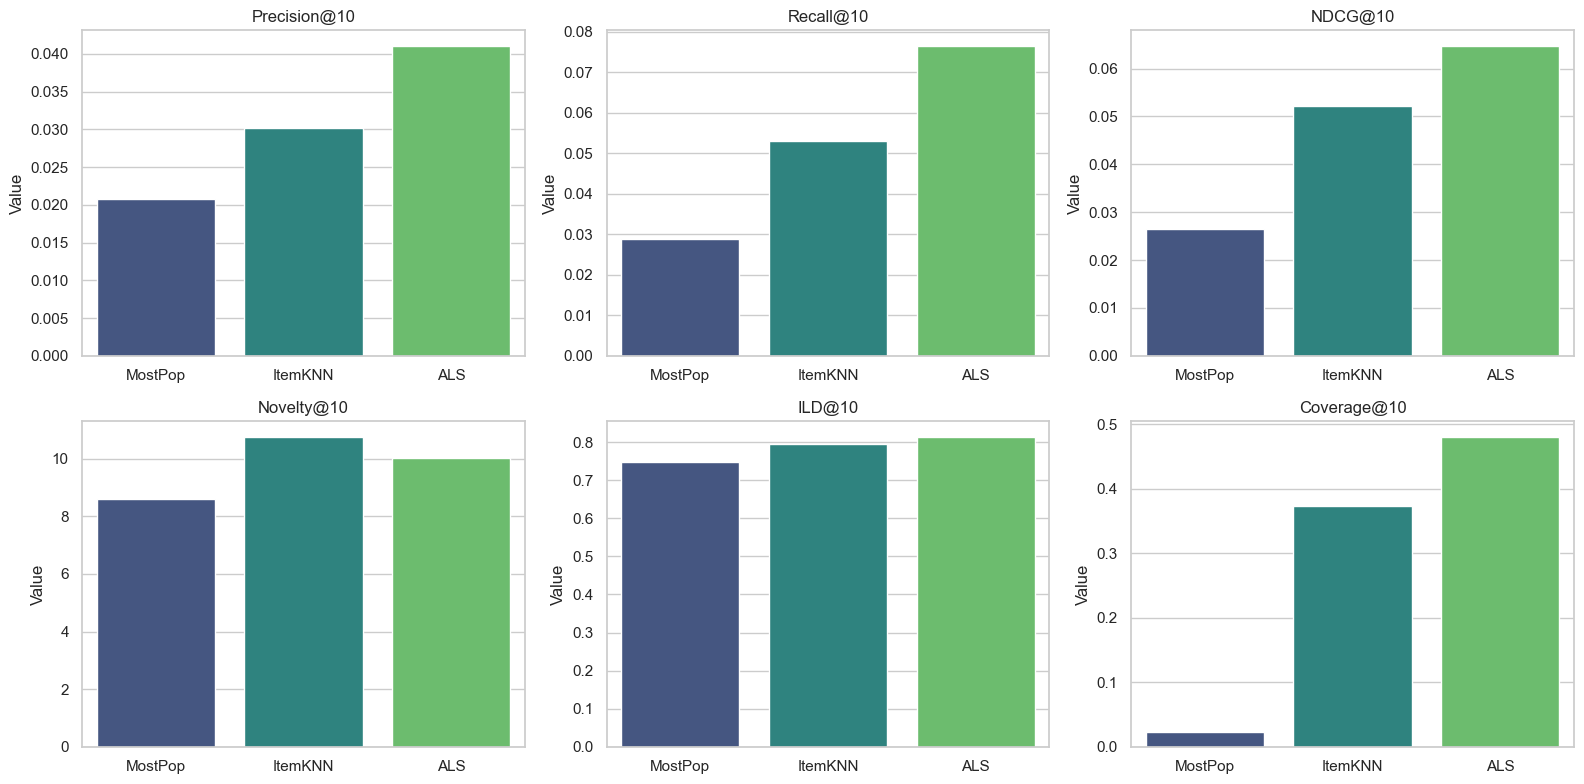

In [30]:
melted_results = results_summary_df.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Value")
metric_order = [f"Precision@{TOP_K}", f"Recall@{TOP_K}", f"NDCG@{TOP_K}", f"Novelty@{TOP_K}", f"ILD@{TOP_K}", f"Coverage@{TOP_K}"]
comparison_figure, comparison_axes = plt.subplots(2, 3, figsize=(16, 8))
for metric_name, metric_axis in zip(metric_order, comparison_axes.ravel()):
    metric_slice = melted_results[melted_results["Metric"] == metric_name]
    sns.barplot(data=metric_slice, x="Model", y="Value", hue="Model", palette="viridis", legend=False, ax=metric_axis)
    metric_axis.set_title(metric_name)
    metric_axis.set_xlabel("")
comparison_figure.tight_layout()
plt.show()

**Интерпретация графиков. Итоговые выводы**

Графики подтверждают таблицу: на панелях точности (Precision/Recall/NDCG) столбцы монотонно растут MostPop -> ItemKNN -> ALS; на панели Novelty пик у ItemKNN; на Coverage бейзлайн уступает персонализированным моделям более чем в 20 раз (0.0224 против 0.4802).

**Выводы по работе:**
1. Построен полный воспроизводимый пайплайн на реальном открытом датасете: загрузка -> EDA -> очистка (гости 24.9%) -> персональный временной split 80/20 без утечек -> CSR-матрица 4094×3133 (плотность 1.72%).
2. Реализованы и честно сравнены три семейства методов; ALS уверенно превосходит эвристический бейзлайн (NDCG@10 ×2.4, Recall ×2.7, Coverage ×21), ItemKNN дает максимальную новизну.
3. Набор из 6 метрик показал, что оптимизация только точности скрывает важные свойства: банальность и каталожный охват бейзлайна, trade-off новизны у KNN.